# torchvision detectors: Faster R-CNN (two-stage) and RetinaNet (one-stage), both anchor-based

COCO-pretrained ResNet-50 FPN v2 models fine-tuned under the same protocol as `02_ultralytics`: every 5th training frame, long side 1280 px, ignore regions greyed out in training only, validation and test predicted on untouched frames, one evaluator. Each run is one entry in `EXPERIMENTS`; every tuned run changes one setting of its baseline.

In [1]:
import json
import math
import random
import sys
import time
from collections import defaultdict
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, retinanet, retinanet_resnet50_fpn_v2
from torchvision.models.detection.anchor_utils import AnchorGenerator
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.ops import sigmoid_focal_loss

ROOT = Path.cwd() if Path("src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.data import export_yolo, load, select_frames
from src.evaluate import evaluate, to_coco
from src.predict import load_image, predict_tiled, predict_torchvision
from src.submission import write_submission

KAGGLE = Path("/kaggle/input").exists()
DATA = next(Path("/kaggle/input").rglob("train/annotations_coco.json")).parents[1] if KAGGLE else ROOT / "data/raw"
WORK = Path("/kaggle/working") if KAGGLE else ROOT / "runs/local"
PREPARED = Path("/kaggle/temp/yolo") if KAGGLE else WORK / "yolo"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # one GPU; the second T4 stays idle

EXPERIMENTS = {  # lr follows torchvision's reference recipes scaled to batch 4
    "frcnn_1280_5ep": dict(arch="fasterrcnn", lr=0.005),
    "frcnn_1280_5ep_anchor16": dict(arch="fasterrcnn", lr=0.005, anchor=16),
    "frcnn_1280_5ep_prop3000": dict(arch="fasterrcnn", lr=0.005, proposals=3000),
    "retina_1280_5ep": dict(arch="retinanet", lr=0.0025),
    "retina_1280_5ep_anchor16": dict(arch="retinanet", lr=0.0025, anchor=16),
    "retina_1280_5ep_gamma1": dict(arch="retinanet", lr=0.0025, gamma=1.0),
    # 960 px crops make an epoch ~4.5x longer: every 10th frame, 2 epochs, batch 2 for 1280x1280 inputs
    "frcnn_1280_2ep_anchor16_tile960": dict(arch="fasterrcnn", lr=0.0025, anchor=16, tile=960, epochs=2, batch=2, train_stride=10),
}
RUN = "frcnn_1280_2ep_anchor16_tile960"
CFG = {"imgsz": 1280, "epochs": 5, "batch": 4, "anchor": 32, "proposals": None, "gamma": 2.0, "tile": None, "warmup": 500,
       "train_stride": 5, "curve_stride": 10, "seed": 42, **EXPERIMENTS[RUN]}
RUN_DIR = next(Path("/kaggle/input").rglob(RUN), None) if KAGGLE else None  # finished run attached as input
random.seed(CFG["seed"]); np.random.seed(CFG["seed"]); torch.manual_seed(CFG["seed"])
print(RUN, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else DEVICE)

frcnn_1280_2ep_anchor16_tile960 | Tesla T4


## Data

The same export as for YOLO: grey ignore regions, boxes more than half inside them dropped, long side shrunk to 1280 px. With `tile`, every frame also gives its 960 px crops at original resolution (as in `02_ultralytics`), which the model enlarges to 1280 px. The YOLO label files are read back as corner boxes.

In [2]:
train_coco, val_coco = load(DATA / "train/annotations_coco.json"), load(DATA / "val/annotations_coco.json")
test = pd.read_csv(DATA / "test_images.csv")
export_yolo(train_coco, DATA / "train", PREPARED, "train", CFG["train_stride"], CFG["imgsz"], CFG["tile"])
del train_coco  # 1.1M train boxes are not needed after export

train = []  # (image path, normalised x1 y1 x2 y2, class 0-7)
for label in sorted((PREPARED / "labels/train").glob("*.txt")):
    rows = np.array([line.split() for line in label.read_text().splitlines()], float).reshape(-1, 5)
    c, (cx, cy, w, h) = rows[:, 0].astype(int), rows[:, 1:].T
    train.append((PREPARED / "images/train" / f"{label.stem}.jpg", np.c_[cx - w / 2, cy - h / 2, cx + w / 2, cy + h / 2], c))
curve_frames = [(i["id"], DATA / "val" / i["file_name"]) for i in select_frames(val_coco, CFG["curve_stride"])]
print(len(train), "train frames |", len(curve_frames), "val frames for the training curve")

11138 train frames | 288 val frames for the training curve


## Anchors against object sizes

The square root of box area in training pixels (after the shrink to 1280 px), compared with the smallest anchor. torchvision's default smallest anchor is 32 px; the `anchor16` runs halve every anchor size.

In [3]:
sizes = np.concatenate([np.sqrt((b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])) * 1280 for _, b, _ in train[::10]])
print("box size quantiles (px):", dict(zip(["5%", "25%", "50%", "75%", "95%"], np.percentile(sizes, [5, 25, 50, 75, 95]).round(1))))
print(f"smaller than 32 px: {(sizes < 32).mean():.0%} | smaller than 16 px: {(sizes < 16).mean():.0%}")

box size quantiles (px): {'5%': np.float64(22.5), '25%': np.float64(36.9), '50%': np.float64(52.8), '75%': np.float64(79.3), '95%': np.float64(149.2)}
smaller than 32 px: 17% | smaller than 16 px: 1%


## Models

Faster R-CNN: RPN proposals from 3 anchors per location (one size per FPN level, ratios 0.5, 1, 2), then RoI Align and a box head with 8 classes + background. RetinaNet: 9 anchors per location (3 sizes x 3 ratios) on P3-P7, sigmoid focal loss for classes and GIoU loss for boxes. Changing anchor sizes keeps the anchor count per location, so all COCO weights still load. Both keep up to 500 boxes per image with scores down to 0.001.

In [4]:
def build_model(cfg):
    scales = [cfg["anchor"] * 2 ** k for k in range(5)]
    if cfg["arch"] == "fasterrcnn":
        p = cfg["proposals"] or 1000
        model = fasterrcnn_resnet50_fpn_v2(weights="DEFAULT", min_size=cfg["imgsz"], max_size=cfg["imgsz"],
                                           box_score_thresh=0.001, box_detections_per_img=500,
                                           rpn_pre_nms_top_n_train=max(2 * p, 2000), rpn_post_nms_top_n_train=max(2 * p, 2000),
                                           rpn_pre_nms_top_n_test=p, rpn_post_nms_top_n_test=p)
        model.roi_heads.box_predictor = FastRCNNPredictor(model.roi_heads.box_predictor.cls_score.in_features, 9)
        model.rpn.anchor_generator = AnchorGenerator(tuple((s,) for s in scales), ((0.5, 1.0, 2.0),) * 5)
    else:
        model = retinanet_resnet50_fpn_v2(weights="DEFAULT", min_size=cfg["imgsz"], max_size=cfg["imgsz"],
                                          score_thresh=0.001, detections_per_img=500)
        head = model.head.classification_head  # new 9-way output (label 0 unused), COCO weights kept below it
        head.num_classes = 9
        head.cls_logits = nn.Conv2d(256, head.num_anchors * 9, 3, padding=1)
        nn.init.normal_(head.cls_logits.weight, std=0.01)
        nn.init.constant_(head.cls_logits.bias, -math.log(99))  # prior probability 0.01, as in the RetinaNet paper
        model.anchor_generator = AnchorGenerator(tuple((s, int(s * 2 ** (1 / 3)), int(s * 2 ** (2 / 3))) for s in scales),
                                                 ((0.5, 1.0, 2.0),) * 5)
        retinanet.sigmoid_focal_loss = partial(sigmoid_focal_loss, gamma=cfg["gamma"])
    return model.to(DEVICE)

model = build_model(CFG)
print(CFG["arch"], f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f}M parameters")

fasterrcnn 43.3M parameters


## Training

SGD with momentum 0.9 and weight decay 1e-4, linear warmup for 500 steps, cosine decay, mixed precision, horizontal flips. JPEGs are decoded on the GPU. After every epoch the model is scored on every 10th validation frame (untouched frames, same evaluator); the best epoch is kept as `best.pt`.

In [5]:
if RUN_DIR is None:
    RUN_DIR = WORK / RUN
    RUN_DIR.mkdir(parents=True, exist_ok=True)
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.SGD(params, lr=CFG["lr"], momentum=0.9, weight_decay=1e-4)
    total = CFG["epochs"] * math.ceil(len(train) / CFG["batch"])
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda it: min(1, (it + 1) / CFG["warmup"]) * 0.5 * (1 + math.cos(math.pi * it / total)))
    scaler = torch.amp.GradScaler(enabled=DEVICE == "cuda")
    history, start = [], time.time()
    for epoch in range(1, CFG["epochs"] + 1):
        model.train()
        losses_sum, order = defaultdict(float), np.random.permutation(len(train))
        for k in range(0, len(order), CFG["batch"]):
            images, targets = [], []
            for i in order[k:k + CFG["batch"]]:
                path, boxes, classes = train[i]
                image = load_image(path, DEVICE)
                H, W = image.shape[1:]
                boxes = torch.tensor(boxes, dtype=torch.float32, device=DEVICE) * torch.tensor([W, H, W, H], device=DEVICE)
                if random.random() < 0.5:
                    image, boxes = image.flip(-1), torch.stack([W - boxes[:, 2], boxes[:, 1], W - boxes[:, 0], boxes[:, 3]], 1)
                images.append(image)
                targets.append({"boxes": boxes, "labels": torch.tensor(classes + 1, device=DEVICE)})
            with torch.autocast("cuda", torch.float16, enabled=DEVICE == "cuda"):
                losses = model(images, targets)
            optimizer.zero_grad()
            scaler.scale(sum(losses.values())).backward()
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            for name, value in losses.items():
                losses_sum[name] += value.item() * CFG["batch"] / len(train)
        score = evaluate(val_coco, predict_torchvision(model, curve_frames, DEVICE)[0])
        history.append({"epoch": epoch, "time": time.time() - start, **losses_sum, "mAP": score["mAP"], "AP50": score["AP50"]})
        torch.save(model.state_dict(), RUN_DIR / "last.pt")
        if score["mAP"] >= max(h["mAP"] for h in history):
            torch.save(model.state_dict(), RUN_DIR / "best.pt")
        print(f'epoch {epoch} | loss {sum(losses_sum.values()):.3f} | val mAP {score["mAP"]:.4f} | {history[-1]["time"] / 60:.0f} min')
    pd.DataFrame(history).to_csv(RUN_DIR / "results.csv", index=False)
print(RUN_DIR)

epoch 1 | loss 0.748 | val mAP 0.2304 | 47 min
epoch 2 | loss 0.610 | val mAP 0.2255 | 94 min
/kaggle/working/frcnn_1280_2ep_anchor16_tile960


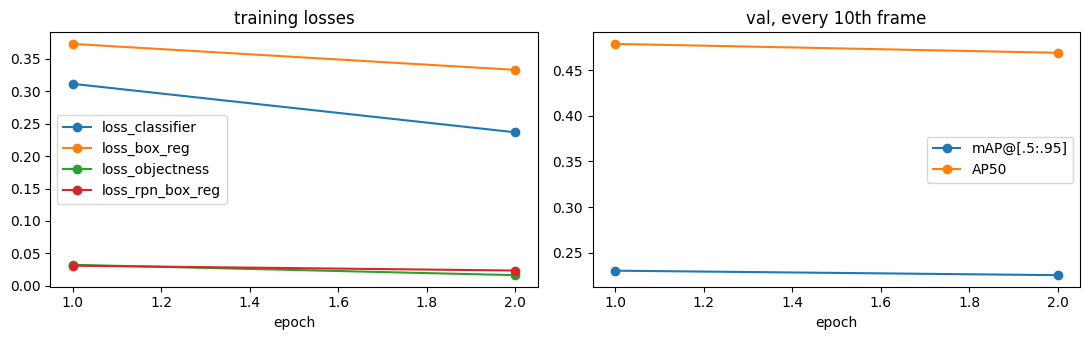

training time: 1.56 h


In [6]:
curve = pd.read_csv(RUN_DIR / "results.csv")
train_hours = curve.time.iloc[-1] / 3600
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for name in curve.columns.drop(["epoch", "time", "mAP", "AP50"]):
    axes[0].plot(curve.epoch, curve[name], marker="o", label=name)
axes[0].set_title("training losses")
axes[1].plot(curve.epoch, curve.mAP, marker="o", label="mAP@[.5:.95]")
axes[1].plot(curve.epoch, curve.AP50, marker="o", label="AP50")
axes[1].set_title(f"val, every {CFG['curve_stride']}th frame")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.legend()
plt.tight_layout()
plt.show()
print(f"training time: {train_hours:.2f} h")

## Validation: all 2,846 frames, best checkpoint (with `tile`: whole frame plus crops, merged as in `02_ultralytics`)

In [7]:
model.load_state_dict(torch.load(RUN_DIR / "best.pt", map_location=DEVICE))
val_frames = [(i["id"], DATA / "val" / i["file_name"]) for i in select_frames(val_coco)]
predict = partial(predict_tiled, imgsz=CFG["imgsz"], tile=CFG["tile"]) if CFG["tile"] else partial(predict_torchvision, device=DEVICE)
val_dets, ms_img = predict(model, val_frames)
metrics = evaluate(val_coco, val_dets)
(WORK / "val_predictions.json").write_text(json.dumps(to_coco(val_dets)))
pd.DataFrame([{**metrics, "ms_img": ms_img, "empty_images": sum(len(b) == 0 for b, _, _ in val_dets.values())}]).round(4)

,mAP,AP50,AP_small,AP_medium,AP_large,ms_img,empty_images
0,0.2499,0.5168,0.1228,0.2443,0.3931,858.1132,0


## Test predictions

In [8]:
test_dets, _ = predict(model, [(r.image_id, DATA / r.file_name) for r in test.itertuples()])
write_submission(test, test_dets, WORK / "submission.csv")
row = dict(run_id=RUN, status="completed", model=f'{CFG["arch"]}_resnet50_fpn_v2', seed=CFG["seed"], train_stride=CFG["train_stride"],
           train_frames=len(train), val_frames=len(val_frames), epochs=CFG["epochs"], imgsz=CFG["imgsz"], **metrics,
           ms_img=ms_img, gpu_hours=train_hours, public_lb=None,
           notes=f'1 GPU, batch {CFG["batch"]}, SGD {CFG["lr"]} cosine, anchor {CFG["anchor"]}, proposals {CFG["proposals"] or 1000}, gamma {CFG["gamma"]}, tile {CFG["tile"]}, best.pt')
pd.DataFrame([row]).to_csv(WORK / "experiment.csv", index=False)
print("DONE:", len(test), "rows in submission.csv")

DONE: 3811 rows in submission.csv
